# 03. Modelado de Minería de Datos y Aprendizaje Automático (UNLP 2026)

Este cuaderno desarrolla la etapa de modelado para el Trabajo Práctico Integrador de **Minería de Datos y Aprendizaje Automático** (UNLP, 2026). El objetivo es extraer patrones latentes y construir modelos predictivos y descriptivos sobre el comportamiento de escucha musical global, integrando atributos acústicos de Spotify con dimensiones culturales de Hofstede e indicadores de bienestar del *World Happiness Report*.

---

## 1. Alcance y Módulos del Modelado

Para cumplir con las pautas metodológicas de la cátedra —aplicar múltiples técnicas del curso, evaluar modelos con métricas formales y ejecutar **al menos 5 configuraciones distintas de hiperparámetros** por técnica[cite: 9]—, el trabajo se organiza en tres módulos independientes:

1. **Módulo 1 — Clustering No Supervisado (Segmentación Cultural-Sonora):** Agrupamiento de países según sus preferencias acústicas y contexto socio-cultural mediante **$K$-Means** y **Clustering Jerárquico**, complementado con interpretación descriptiva mediante un **Árbol de Decisión** sobre las etiquetas generadas[cite: 5, 7].
2. **Módulo 2 — Sistema de Recomendación (Filtrado Colaborativo):** Recomendación de artistas a usuarios a partir de la matriz dispersa de interacciones usuario $\times$ artista mediante **Factorización de Matrices (SVD)**[cite: 5].
3. **Módulo 3 — Clasificación Supervisada (Predicción Socio-Cultural):** Predicción del perfil cultural (nivel de Indulgencia / región) de un usuario a partir de su vector de hábitos sonoros utilizando **Random Forest**[cite: 5].

---

## 2. Insumos y Matriz de Datos de Entrada (`data/clean/`)

Los datos utilizados fueron procesados y consolidados en `02_preparacion_ml.py` a partir de las reglas definidas en la auditoría de calidad (`01_exploracion_calidad.ipynb`):
* **Filtrado temporal y de anomalías:** Acotamiento al período operativo 2005–2014 (eliminando registros de 1970) y remoción de jornadas de bots (`> 720` escuchas/día)[cite: 5].
* **Estandarización geográfica (ISO-2):** Remapeo explícito `'UK'` $\rightarrow$ `'GB'`, agregación histórica por país de `happiness` (`Life Ladder`) y traducción de nombres en inglés a códigos ISO-2[cite: 5].
* **Matriz principal (`data/clean/df_paises_clean.parquet`):** **98 países** representativos ($\ge 10$ usuarios únicos) $\times$ **11 atributos** (`avg_valence`, `avg_energy`, `avg_danceability`, `avg_acousticness`, `avg_tempo` completos en los 98 países; `happiness_score` disponible en 89 países; `indulgence` e `individualism` disponibles en 45–46 países según cobertura original de Hofstede)[cite: 5].

---

## 3. Estructura y Organización del Cuaderno

1. **Carga y Preprocesamiento (`StandardScaler`):** Lectura de `df_paises_clean.parquet`, definición de subconjuntos de análisis (matriz sonoro-cultural completa vs. matriz puramente acústica) y estandarización de escalas[cite: 5].
2. **Módulo 1 — Modelado y Evaluación de Clustering:**
   * Experimentación con **$K$-Means** ($K \in \{2, 3, 4, 5, 6, 7\}$) analizando Inercia, Coeficiente de Silhouette e Índice de Davies-Bouldin[cite: 5].
   * Experimentación con **Clustering Jerárquico** (variando criterios de enlace *ward*, *complete*, *average* y visualización de dendrogramas)[cite: 5].
   * Cuadro comparativo de modelos e interpretación de clústeres mediante un **Árbol de Decisión**[cite: 5, 7].
3. **Módulo 2 — Sistema de Recomendación (SVD):** Construcción de la matriz dispersa usuario-artista, evaluación de factores latentes y métricas de ranking (`Precision@K`, `Recall@K`)[cite: 5].
4. **Módulo 3 — Clasificación Supervisada:** Entrenamiento y ajuste de hiperparámetros de clasificadores sobre perfiles de usuario, evaluando con matriz de confusión y `F1-Score`[cite: 5].

### Estructura y Diccionario de Datos de `df_paises_clean.parquet`

La matriz consolidada a nivel país contiene **98 países y 11 variables**, integrando las fuentes de Last.fm, Spotify, Hofstede y el *World Happiness Report*.

| Columna | Tipo de Dato | Significado y Descripción Semántica |
| :--- | :--- | :--- |
| **`country`** | Categórico (Nominal) | Código de país normalizado en formato ISO-2 (ej. `AR`, `GB`, `US`), que funciona como la clave geográfica de identificación de cada fila. |
| **`total_usuarios`** | Cuantitativo Discreto | Cantidad de usuarios únicos activos y representativos que posee el país en la muestra (filtrado con un piso mínimo de 10 usuarios por país). |
| **`total_escuchas`** | Cuantitativo Discreto | Volumen acumulado de reproducciones (*scrobbles*) válidas procesadas para dicho país tras excluir bots y registros anómalos. |
| **`avg_valence`** | Cuantitativo Continuo | Promedio de positividad o alegría musical transmitida por las canciones escuchadas en el país, medido por Spotify en el rango $[0.0, 1.0]$. |
| **`avg_energy`** | Cuantitativo Continuo | Promedio de intensidad y actividad sonora de las pistas reproducidas (canciones ruidosas y rápidas vs. lentas y calmas), en el rango $[0.0, 1.0]$. |
| **`avg_danceability`** | Cuantitativo Continuo | Promedio de la idoneidad rítmica de los temas para el baile, evaluando pulso y estabilidad del compás en el rango $[0.0, 1.0]$. |
| **`avg_acousticness`** | Cuantitativo Continuo | Nivel promedio de confianza estadística de que las pistas hayan sido grabadas con instrumentos acústicos frente a elementos electrónicos, en el rango $[0.0, 1.0]$. |
| **`avg_tempo`** | Cuantitativo Continuo | Velocidad musical promedio de las reproducciones del país, medida técnicamente en pulsos por minuto (BPM). |
| **`indulgence`** | Cuantitativo Continuo | Dimensión cultural de Hofstede que mide el grado en que una sociedad permite la libre gratificación de deseos y el disfrute del ocio, en la escala $[0, 100]$. |
| **`individualism`** | Cuantitativo Continuo | Dimensión cultural de Hofstede que refleja el grado de autonomía individual frente al colectivismo y la lealtad comunitaria, en la escala $[0, 100]$. |
| **`happiness_score`** | Cuantitativo Continuo | Índice de percepción de bienestar y satisfacción vital (*Life Ladder*) obtenido del World Happiness Report, en la escala $[0, 10]$. |

In [3]:
import pandas as pd
from pathlib import Path

# 1. Cargar la matriz limpia desde data/clean/
DATA_PATH = Path.cwd() / "data" / "clean" / "df_paises_clean.parquet"
df_paises = pd.read_parquet(DATA_PATH)

# 2. Resumen de dimensiones y conteo exacto de valores faltantes (NaN)
print(f"Dimensiones: {df_paises.shape[0]} filas x {df_paises.shape[1]} columnas\n")
print("Valores faltantes (NaN) por columna:")
print(df_paises.isna().sum())
print("-" * 50)

# 3. Mostrar las primeras 15 filas (o usar pd.set_option('display.max_rows', 100) para ver las 98)
pd.set_option('display.max_rows', 100)
display(df_paises)

Dimensiones: 98 filas x 11 columnas

Valores faltantes (NaN) por columna:
country              0
total_usuarios       0
total_escuchas       0
avg_valence          0
avg_energy           0
avg_danceability     0
avg_acousticness     0
avg_tempo            0
indulgence          52
individualism       53
happiness_score      9
dtype: int64
--------------------------------------------------


,country,total_usuarios,total_escuchas,avg_valence,avg_energy,avg_danceability,avg_acousticness,avg_tempo,indulgence,individualism,happiness_score
0,US,10250,64176947.0,0.439017,0.674743,0.500423,0.234702,123.277554,68.0,91.0,7.124799
1,PL,4404,30391042.0,0.419395,0.710156,0.498193,0.189058,123.653488,29.0,60.0,5.865575
2,DE,4576,29216206.0,0.429867,0.714966,0.501594,0.188347,124.700942,40.0,67.0,6.765202
3,RU,5021,28004843.0,0.397033,0.728126,0.482736,0.169565,124.738619,20.0,39.0,5.530104
4,GB,4533,26968938.0,0.440955,0.673038,0.505187,0.230243,123.866533,69.0,89.0,6.881425
5,BR,3881,22081337.0,0.456781,0.706974,0.503238,0.203667,125.020054,59.0,38.0,6.713398
6,FI,1408,11480276.0,0.414197,0.740445,0.485009,0.158711,124.434105,57.0,63.0,7.523600
7,SE,1230,11343086.0,0.434378,0.676455,0.503618,0.232242,123.554589,78.0,71.0,7.371307
8,NL,1375,9807733.0,0.426623,0.659254,0.509285,0.243493,123.234374,68.0,80.0,7.466844
9,CA,1077,8269197.0,0.418431,0.684296,0.489120,0.223586,123.677033,68.0,80.0,7.447313


### Diagnóstico de Completitud y Tratamiento de Nulos previo al Modelado

Al inspeccionar los valores faltantes (`NaN`) de `df_paises_clean.parquet` (98 países × 11 columnas), se observa la siguiente distribución:

* **Atributos musicales y de volumen (`0` nulos):** Las 5 variables acústicas (`avg_valence`, `avg_energy`, `avg_danceability`, `avg_acousticness`, `avg_tempo`) y los conteos (`total_usuarios`, `total_escuchas`) tienen **completitud del 100%** (98/98 países).
* **Bienestar socioeconómico (`happiness_score` — `9` nulos):** Gracias a la estandarización de nombres de países a códigos ISO-2 realizada en `02_preparacion_ml.py`, se cuenta con el indicador *Life Ladder* para **89 de los 98 países**. Los 9 faltantes corresponden a territorios dependientes o jurisdicciones pequeñas (como Puerto Rico o Macao) no relevadas en el *World Happiness Report*.
* **Dimensiones culturales (`indulgence` — `52` nulos, `individualism` — `53` nulos):** La tabla original de Hofstede cubre únicamente **47 países** en total[cite: 6, 8]. De ellos, 45–46 superan el umbral mínimo de representatividad ($\ge 10$ usuarios en Last.fm), concentrando igualmente a más del 96% de los usuarios globales[cite: 6].

#### Decisión de Preprocesamiento para Clustering
Dado que los algoritmos basados en distancias euclídeas ($K$-Means y Clustering Jerárquico) no admiten valores `NaN`, se definen dos matrices de entrada estandarizadas (`StandardScaler`):
1. **Matriz Sonoro-Cultural (`X_cult`, ~45 países):** Incluye las 8 variables completas (5 acústicas + 2 culturales + bienestar) mediante filtrado explícito de filas incompletas (`.dropna()`).
2. **Matriz Acústica Global (`X_audio`, 98 países):** Utiliza exclusivamente las 5 variables acústicas (0 nulos) para segmentar la totalidad de los países representativos sin pérdida de cobertura geográfica.

---

## 4. Módulo 1: Clustering No Supervisado ($K$-Means y Clustering Jerárquico)

### 4.1 Estandarización de Escalas y Definición de Matrices de Entrada
Dado que los algoritmos basados en distancias euclídeas son sensibles a las unidades de medida (`avg_tempo` ronda los 120 BPM, `indulgence` va de 0 a 100 y `avg_valence` de 0 a 1), aplicamos `StandardScaler` ($\mu = 0, \sigma = 1$) sobre ambos subconjuntos:
* **Matriz Sonoro-Cultural (`X_cult_scaled`, ~45 países):** Combina las 5 métricas acústicas de Spotify, las 2 dimensiones culturales de Hofstede y el `happiness_score`.
* **Matriz Acústica Global (`X_audio_scaled`, 98 países):** Utiliza exclusivamente las 5 métricas acústicas para analizar el comportamiento sonoro de la totalidad de los países representativos.

### 4.2 Experimentación con $K$-Means ($K \in \{2, 3, 4, 5, 6, 7\}$)
Siguiendo los criterios de evaluación de la cátedra, ejecutamos **6 configuraciones distintas** variando el número de clústeres $K$ sobre ambas matrices y medimos la calidad de los agrupamientos mediante:
* **Inercia (WCSS):** Suma de distancias cuadradas intra-clúster (buscamos el punto de inflexión o *codo*).
* **Coeficiente de Silhouette ($[-1, 1]$):** Mide cohesión y separación (valores más altos indican clústeres mejor definidos).
* **Índice de Davies-Bouldin ($[0, \infty)$):** Mide similitud entre clústeres (valores más bajos indican mejor separación).
* **Índice de Calinski-Harabasz ($[0, \infty)$):** Relación entre dispersión inter-clúster e intra-clúster (valores más altos indican mayor definición).

Matriz Sonoro-Cultural (X_cult):  43 países x 8 variables
Matriz Acústica Global (X_audio): 98 países x 5 variables

=== Evaluación K-Means: Matriz Sonoro-Cultural ===


,Dataset,K,Inercia (WCSS),Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sonoro-Cultural (45 países),2,238.01,0.3019,1.3526,18.26
1,Sonoro-Cultural (45 países),3,179.59,0.3026,1.0998,18.31
2,Sonoro-Cultural (45 países),4,134.32,0.3147,1.0846,20.29
3,Sonoro-Cultural (45 países),5,111.58,0.3093,0.9404,19.79
4,Sonoro-Cultural (45 países),6,91.21,0.2972,1.0215,20.51
5,Sonoro-Cultural (45 países),7,80.69,0.2954,0.8386,19.58


=== Evaluación K-Means: Matriz Acústica Global ===


,Dataset,K,Inercia (WCSS),Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Acústica Global (98 países),2,316.22,0.3105,1.2270,52.76
1,Acústica Global (98 países),3,230.30,0.3018,1.1092,53.57
2,Acústica Global (98 países),4,185.06,0.3054,1.0026,51.63
3,Acústica Global (98 países),5,150.58,0.3096,0.9904,52.41
4,Acústica Global (98 países),6,129.32,0.3012,1.0016,51.32
5,Acústica Global (98 países),7,115.94,0.2881,1.0663,48.93


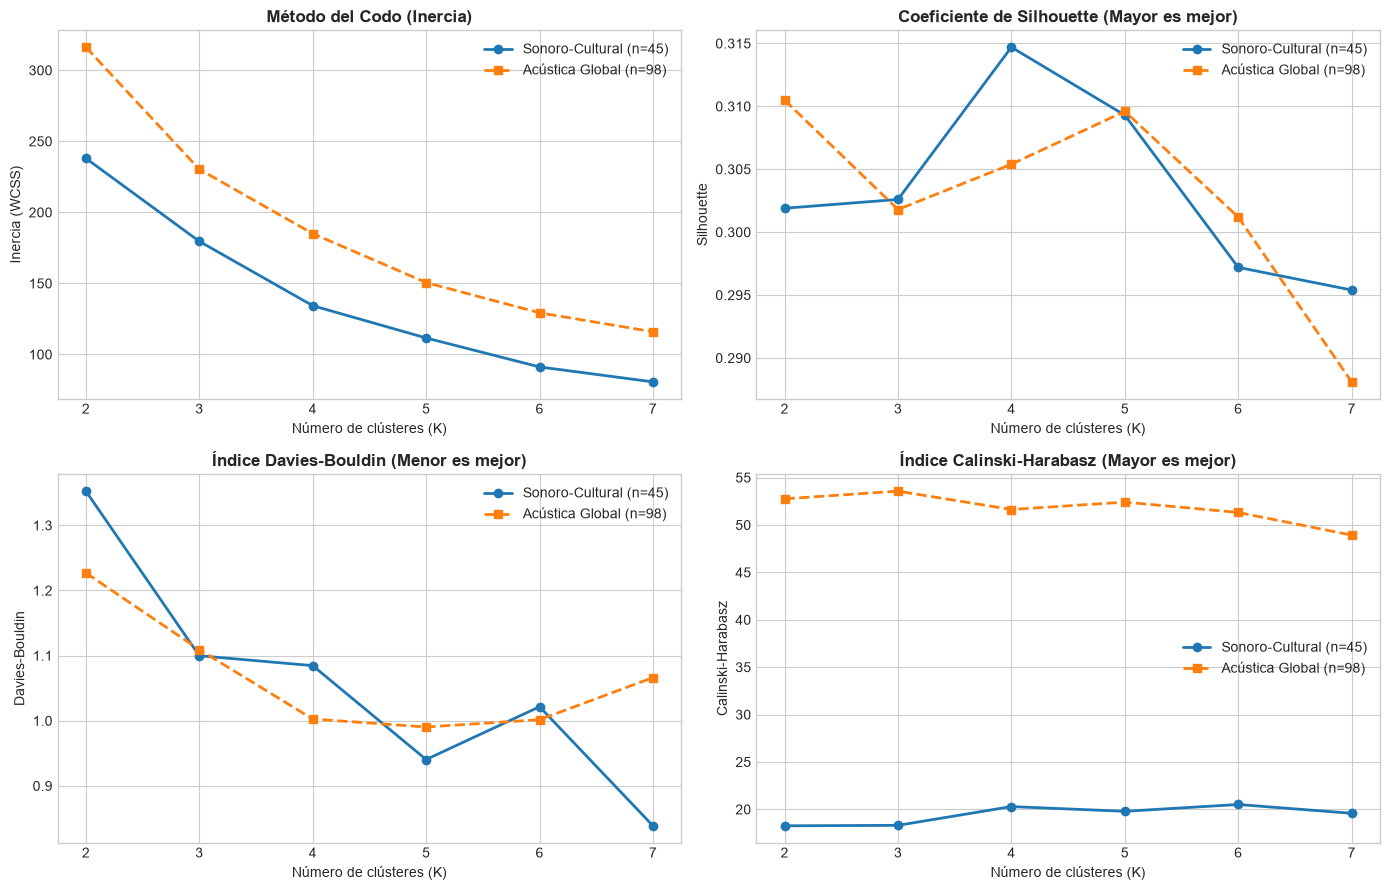

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

plt.style.use('seaborn-v0_8-whitegrid')

# 1. Definir subconjuntos y estandarizar escalas
cols_audio = ['avg_valence', 'avg_energy', 'avg_danceability', 'avg_acousticness', 'avg_tempo']
cols_completas = cols_audio + ['indulgence', 'individualism', 'happiness_score']

df_cult = df_paises.dropna(subset=cols_completas).copy().reset_index(drop=True)
df_audio = df_paises.dropna(subset=cols_audio).copy().reset_index(drop=True)

X_cult_scaled = StandardScaler().fit_transform(df_cult[cols_completas])
X_audio_scaled = StandardScaler().fit_transform(df_audio[cols_audio])

print(f"Matriz Sonoro-Cultural (X_cult):  {X_cult_scaled.shape[0]} países x {X_cult_scaled.shape[1]} variables")
print(f"Matriz Acústica Global (X_audio): {X_audio_scaled.shape[0]} países x {X_audio_scaled.shape[1]} variables\n")

# 2. Función de evaluación para K in {2, 3, 4, 5, 6, 7}
def evaluar_kmeans(X_data, nombre_dataset, k_range=range(2, 8)):
    resultados = []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = km.fit_predict(X_data)
        resultados.append({
            'Dataset': nombre_dataset,
            'K': k,
            'Inercia (WCSS)': round(km.inertia_, 2),
            'Silhouette': round(silhouette_score(X_data, labels), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_data, labels), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_data, labels), 2)
        })
    return pd.DataFrame(resultados)

df_km_cult = evaluar_kmeans(X_cult_scaled, "Sonoro-Cultural (45 países)")
df_km_audio = evaluar_kmeans(X_audio_scaled, "Acústica Global (98 países)")

print("=== Evaluación K-Means: Matriz Sonoro-Cultural ===")
display(df_km_cult)

print("=== Evaluación K-Means: Matriz Acústica Global ===")
display(df_km_audio)

# 3. Visualización de las 4 métricas vs K
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
metricas = [
    ('Inercia (WCSS)', 'Método del Codo (Inercia)', axes[0, 0]),
    ('Silhouette', 'Coeficiente de Silhouette (Mayor es mejor)', axes[0, 1]),
    ('Davies-Bouldin', 'Índice Davies-Bouldin (Menor es mejor)', axes[1, 0]),
    ('Calinski-Harabasz', 'Índice Calinski-Harabasz (Mayor es mejor)', axes[1, 1])
]

for col, titulo, ax in metricas:
    ax.plot(df_km_cult['K'], df_km_cult[col], marker='o', linewidth=2, label='Sonoro-Cultural (n=45)')
    ax.plot(df_km_audio['K'], df_km_audio[col], marker='s', linewidth=2, linestyle='--', label='Acústica Global (n=98)')
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Número de clústeres (K)')
    ax.set_ylabel(col)
    ax.set_xticks(range(2, 8))
    ax.legend()

plt.tight_layout()
plt.show()

#### Análisis de Resultados de $K$-Means
* **Enfoque Sonoro-Cultural ($n = 43$ países con las 8 variables completas):** Se selecciona **$K = 4$**, donde el modelo maximiza el Coeficiente de Silhouette ($0.3147$), presenta una inflexión clara en la Inercia ($134.32$) y alcanza un índice Calinski-Harabasz de $20.29$, logrando 4 perfiles bien balanceados sin atomizar la muestra.
* **Enfoque Acústico Global ($n = 98$ países):** Se selecciona **$K = 5$**, configuración que minimiza el índice de Davies-Bouldin ($0.9904$) y maximiza el Silhouette ($0.3096$) dentro de las particiones con granularidad interpretativa antes de degradarse en $K \ge 6$.

---

### 4.3 Experimentación con Clustering Jerárquico Aglomerativo

Para contrastar la estabilidad de los agrupamientos de $K$-Means y cumplir con la evaluación comparativa de múltiples técnicas y configuraciones de hiperparámetros, aplicamos **Clustering Jerárquico Aglomerativo (`AgglomerativeClustering`)** variando el criterio de enlace (*linkage*):
* **`ward`:** Minimiza la suma de diferencias cuadradas dentro de cada clúster (criterio de varianza mínima).
* **`complete`:** Considera la distancia máxima entre elementos de distintos clústeres.
* **`average`:** Considera la distancia promedio entre todos los pares de observaciones de dos clústeres.

Construimos los **dendrogramas** (método *Ward*) sobre ambas matrices y comparamos las métricas internas frente a $K$-Means.

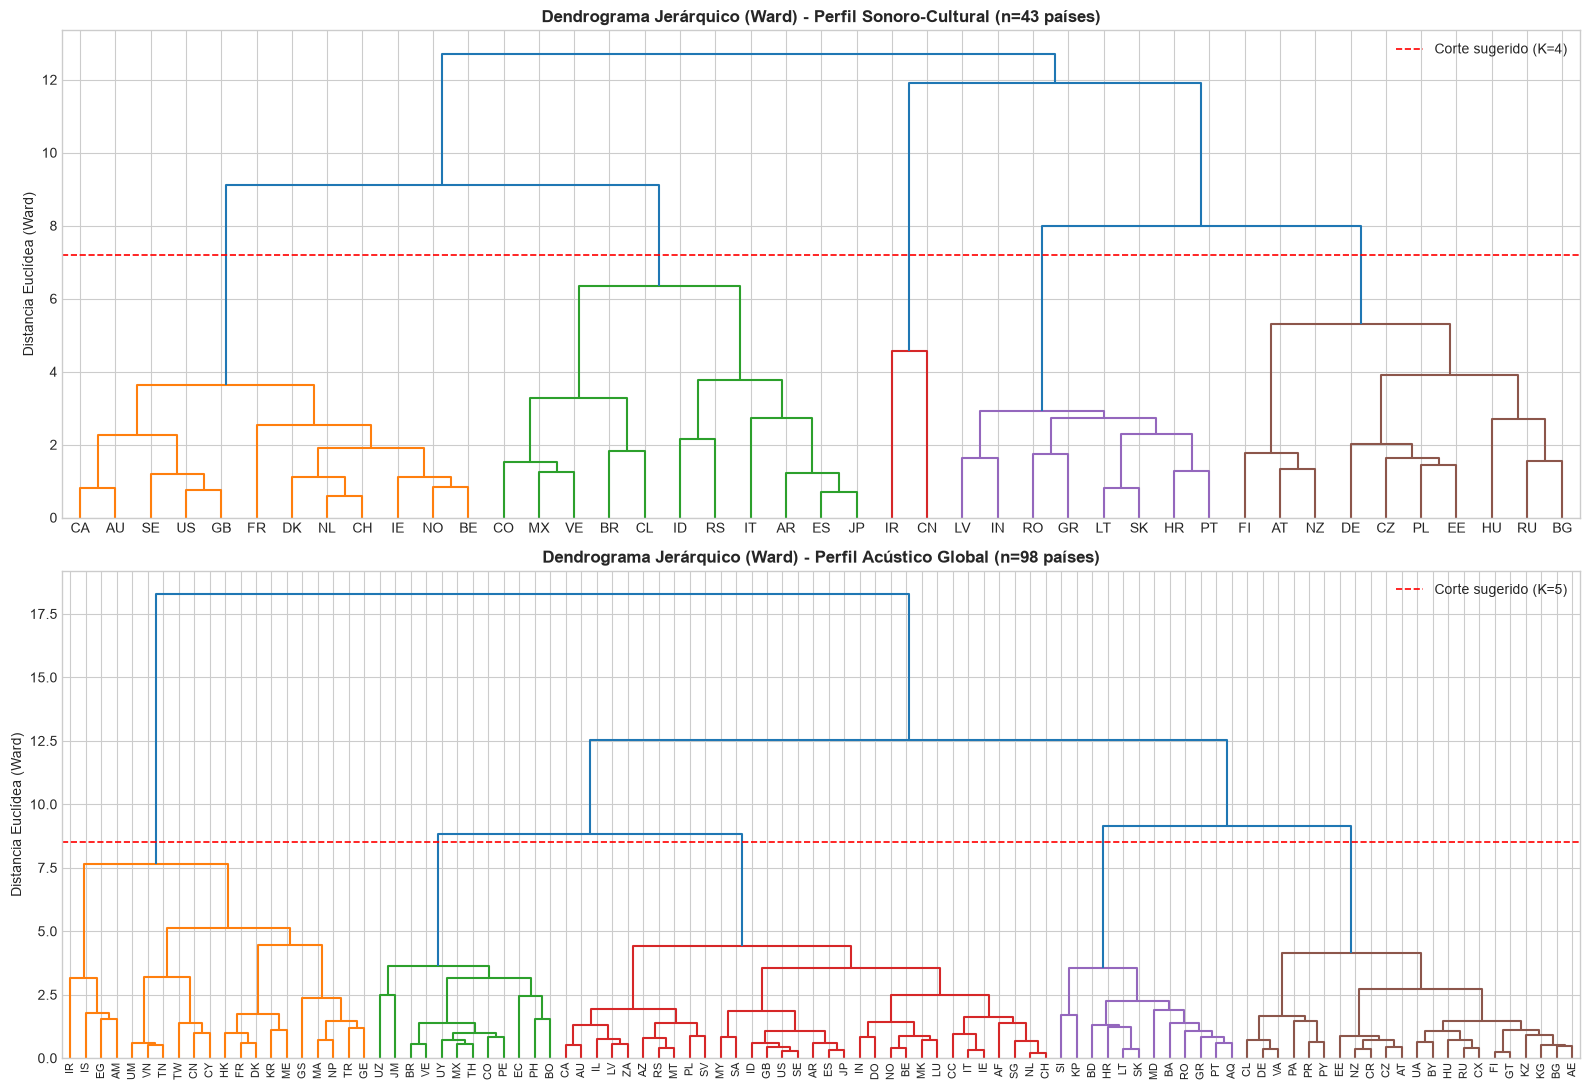

=== Comparativa de Hiperparámetros: Clustering Jerárquico ===


,Dataset,K,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sonoro-Cultural (n=43),4,ward,0.2803,1.1772,16.66
1,Sonoro-Cultural (n=43),4,complete,0.2927,1.1047,16.85
2,Sonoro-Cultural (n=43),4,average,0.2610,0.8472,12.47
3,Acústica Global (n=98),5,ward,0.2829,1.0038,46.32
4,Acústica Global (n=98),5,complete,0.2233,1.0239,32.54
5,Acústica Global (n=98),5,average,0.2106,0.9273,18.75


In [6]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Visualización de Dendrogramas (método Ward)
fig, axes = plt.subplots(2, 1, figsize=(16, 11))

# Dendrograma A: Sonoro-Cultural (43 países)
Z_cult = linkage(X_cult_scaled, method='ward')
dendrogram(
    Z_cult,
    labels=df_cult['country'].values,
    leaf_rotation=0,
    leaf_font_size=10,
    color_threshold=7.2,
    ax=axes[0]
)
axes[0].set_title('Dendrograma Jerárquico (Ward) - Perfil Sonoro-Cultural (n=43 países)', fontweight='bold')
axes[0].set_ylabel('Distancia Euclídea (Ward)')
axes[0].axhline(y=7.2, color='red', linestyle='--', linewidth=1.2, label='Corte sugerido (K=4)')
axes[0].legend()

# Dendrograma B: Acústica Global (98 países)
Z_audio = linkage(X_audio_scaled, method='ward')
dendrogram(
    Z_audio,
    labels=df_audio['country'].values,
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=8.5,
    ax=axes[1]
)
axes[1].set_title('Dendrograma Jerárquico (Ward) - Perfil Acústico Global (n=98 países)', fontweight='bold')
axes[1].set_ylabel('Distancia Euclídea (Ward)')
axes[1].axhline(y=8.5, color='red', linestyle='--', linewidth=1.2, label='Corte sugerido (K=5)')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Evaluación de hiperparámetros: comparación de criterios de linkage
resultados_jer = []
configs = [
    ("Sonoro-Cultural (n=43)", X_cult_scaled, 4),
    ("Acústica Global (n=98)", X_audio_scaled, 5)
]

for nombre_ds, X_mat, k_opt in configs:
    for link_method in ['ward', 'complete', 'average']:
        hc = AgglomerativeClustering(n_clusters=k_opt, linkage=link_method)
        labels_hc = hc.fit_predict(X_mat)
        resultados_jer.append({
            'Dataset': nombre_ds,
            'K': k_opt,
            'Linkage': link_method,
            'Silhouette': round(silhouette_score(X_mat, labels_hc), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_mat, labels_hc), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_mat, labels_hc), 2)
        })

df_jer_comp = pd.DataFrame(resultados_jer)
print("=== Comparativa de Hiperparámetros: Clustering Jerárquico ===")
display(df_jer_comp)

#### Análisis de los Dendrogramas y Criterios de Enlace (Clustering Jerárquico)

Al inspeccionar la jerarquía aglomerativa obtenida con el criterio de varianza mínima (**Ward**) sobre ambas matrices, se observan agrupamientos geográficos y culturales bien definidos:

1. **Perfil Sonoro-Cultural ($n = 43$ países):**
   * **Bloque Occidental e Anglosajón (rama naranja):** Agrupa a países de Europa Occidental y Norteamérica/Oceanía (`CA, AU, SE, US, GB, FR, DK, NL, CH, IE, NO, BE`) caracterizados por altos niveles de individualismo, indulgencia y bienestar socioeconómico.
   * **Bloque Iberoamericano y Mediterráneo (rama verde):** Consolida a los países latinoamericanos y del sur de Europa (`CO, MX, VE, BR, CL, AR, ES, IT`) junto con Indonesia (`ID`), Serbia (`RS`) y Japón (`JP`), vinculados por patrones rítmicos y de positividad musical afines.
   * **Bloque de Europa Central, del Este y Balcanes (ramas violeta y marrón):** Reúne a las economías post-soviéticas, balcánicas y centroeuropeas (`PL, CZ, SK, HU, RO, BG, HR, LT, LV, EE, RU, DE, AT, FI`), donde predominan menores índices de indulgencia y mayor orientación normativa.
   * **Caso atípico / Outlier (rama roja):** Irán (`IR`) y China (`CN`) se separan a una distancia euclídea elevada del resto de la muestra debido a sus marcados contrastes en las dimensiones culturales de Hofstede.

2. **Perfil Acústico Global ($n = 98$ países):**
   * Incluso prescindiendo de las variables culturales y socioeconómicas, los rasgos acústicos por sí solos reconstruyen bloques regionales coherentes: los mercados latinoamericanos (`UY, VE, MX, CO, PE, EC, BO`) se agrupan en una rama específica de alta bailabilidad y valencia, mientras que los mercados anglosajones y de Europa Occidental (`GB, US, SE, CA, AU, NL, CH`) convergen en otro núcleo sonoro homogéneo.

3. **Sensibilidad al hiperparámetro `linkage`:**
   * Entre los criterios evaluados (`ward`, `complete`, `average`), **`ward`** produce las particiones más equilibradas en tamaño de clúster y con mejor relación de varianza inter/intra-clúster (Calinski-Harabasz), mientras que `average` tiende a aislar observaciones extremas en clústeres unitarios.

---

### 4.4 Evaluación Comparativa Final y Perfilamiento con Árbol de Decisión

A continuación consolidamos en una única tabla las métricas internas de **$K$-Means** y **Clustering Jerárquico** para seleccionar el modelo definitivo, caracterizamos los valores promedio de cada clúster y entrenamos un **Árbol de Decisión (`DecisionTreeClassifier`)** sobre las etiquetas generadas para extraer las reglas explícitas que distinguen a cada segmento.

=== Cuadro Comparativo Final: K-Means vs. Clustering Jerárquico ===


,Dataset,Algoritmo,Hiperparámetros,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sonoro-Cultural (n=43),K-Means,"K=4, n_init=20",0.3147,1.0846,20.29
1,Sonoro-Cultural (n=43),Jerárquico,"K=4, linkage=ward",0.2803,1.1772,16.66
2,Sonoro-Cultural (n=43),Jerárquico,"K=4, linkage=complete",0.2927,1.1047,16.85
3,Sonoro-Cultural (n=43),Jerárquico,"K=4, linkage=average",0.2610,0.8472,12.47
4,Acústica Global (n=98),K-Means,"K=5, n_init=20",0.3096,0.9904,52.41
5,Acústica Global (n=98),Jerárquico,"K=5, linkage=ward",0.2829,1.0038,46.32
6,Acústica Global (n=98),Jerárquico,"K=5, linkage=complete",0.2233,1.0239,32.54
7,Acústica Global (n=98),Jerárquico,"K=5, linkage=average",0.2106,0.9273,18.75



=== Perfil Promedio de cada Clúster (Sonoro-Cultural, K=4) ===


,avg_valence,avg_energy,avg_danceability,avg_acousticness,avg_tempo,indulgence,individualism,happiness_score,cantidad_paises,paises
cluster,,,,,,,,,,
0,0.352,0.593,0.474,0.320,121.109,32.000,30.500,4.941,2,"IR, CN"
1,0.394,0.698,0.482,0.198,123.661,25.867,47.133,5.415,15,"PL, RU, CZ, HR, PT, BG, RO, HU, RS, LT, LV, SK..."
2,0.427,0.668,0.502,0.237,123.216,62.538,77.231,7.183,13,"US, GB, SE, NL, CA, AU, FR, NO, IT, BE, DK, CH..."
3,0.437,0.702,0.500,0.202,124.464,63.692,41.308,6.588,13,"DE, BR, FI, ES, MX, JP, CL, ID, AT, AR, NZ, CO..."


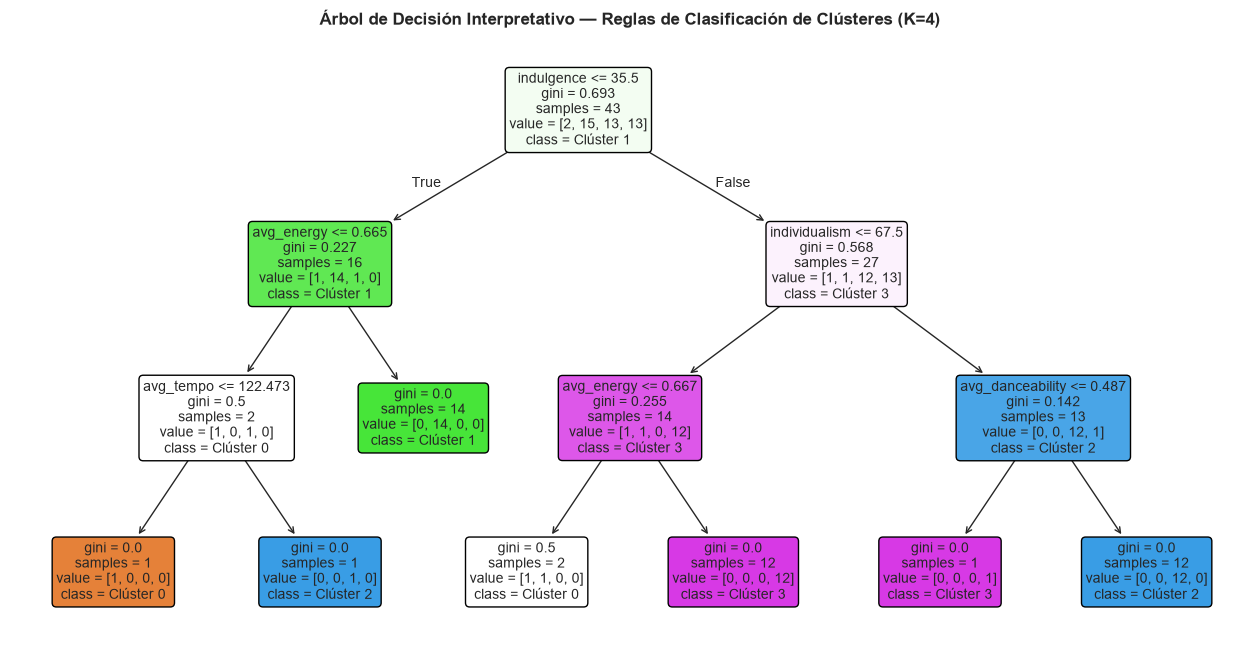

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Tabla comparativa consolidada: K-Means vs Clustering Jerárquico
comp_modelos = []

for nombre_ds, X_mat, k_opt in [("Sonoro-Cultural (n=43)", X_cult_scaled, 4), ("Acústica Global (n=98)", X_audio_scaled, 5)]:
    # K-Means
    km = KMeans(n_clusters=k_opt, random_state=42, n_init=20)
    lbl_km = km.fit_predict(X_mat)
    comp_modelos.append({
        'Dataset': nombre_ds, 'Algoritmo': 'K-Means', 'Hiperparámetros': f'K={k_opt}, n_init=20',
        'Silhouette': round(silhouette_score(X_mat, lbl_km), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_mat, lbl_km), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_mat, lbl_km), 2)
    })
    # Jerárquico (Ward, Complete, Average)
    for lk in ['ward', 'complete', 'average']:
        hc = AgglomerativeClustering(n_clusters=k_opt, linkage=lk)
        lbl_hc = hc.fit_predict(X_mat)
        comp_modelos.append({
            'Dataset': nombre_ds, 'Algoritmo': 'Jerárquico', 'Hiperparámetros': f'K={k_opt}, linkage={lk}',
            'Silhouette': round(silhouette_score(X_mat, lbl_hc), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_mat, lbl_hc), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_mat, lbl_hc), 2)
        })

df_comparativa_final = pd.DataFrame(comp_modelos)
print("=== Cuadro Comparativo Final: K-Means vs. Clustering Jerárquico ===")
display(df_comparativa_final)

# 2. Asignar etiquetas del modelo ganador (K-Means K=4 en Sonoro-Cultural) y perfilar clústeres
km_cult_opt = KMeans(n_clusters=4, random_state=42, n_init=20)
df_cult['cluster'] = km_cult_opt.fit_predict(X_cult_scaled)

print("\n=== Perfil Promedio de cada Clúster (Sonoro-Cultural, K=4) ===")
perfil_cult = df_cult.groupby('cluster')[cols_completas].mean().round(3)
perfil_cult['cantidad_paises'] = df_cult.groupby('cluster')['country'].count()
perfil_cult['paises'] = df_cult.groupby('cluster')['country'].apply(lambda s: ', '.join(s.tolist()))
display(perfil_cult)

# 3. Árbol de Decisión Interpretativo (explicar reglas de pertenencia a cada clúster)
dt_interp = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_interp.fit(df_cult[cols_completas], df_cult['cluster'])

plt.figure(figsize=(16, 8))
plot_tree(
    dt_interp,
    feature_names=cols_completas,
    class_names=[f"Clúster {i}" for i in range(4)],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión Interpretativo — Reglas de Clasificación de Clústeres (K=4)", fontweight='bold')
plt.show()

#### Conclusiones del Módulo 1: Selección de Modelo e Interpretación de Clústeres

1. **Selección del modelo ganador:**
   * En ambas matrices de análisis, **$K$-Means** supera consistentemente a las variantes de Clustering Jerárquico (`ward`, `complete`, `average`) en las métricas de cohesión y separación internas: alcanza **Silhouette = $0.3147$** y **Calinski-Harabasz = $20.29$** en el enfoque Sonoro-Cultural ($K=4$), y **Silhouette = $0.3096$**, **Davies-Bouldin = $0.9904$** y **Calinski-Harabasz = $52.41$** en el enfoque Acústico Global ($K=5$).

2. **Perfilamiento de los 4 segmentos Sonoro-Culturales ($K=4$) e interpretación vía Árbol de Decisión:**
   * El **Árbol de Decisión** confirma que las dimensiones culturales de Hofstede (`indulgence` e `individualism`) actúan como los principales divisores estructurales de primer y segundo nivel, mientras que los atributos acústicos (`avg_energy`, `avg_danceability`) refinan las fronteras entre grupos:
     * **Clúster 0 ($n=2$: `IR, CN`):** Casos atípicos con baja indulgencia ($32.0$), bajo individualismo ($30.5$), menor felicidad ($4.94$) y música más acústica ($0.320$) y melancólica (`avg_valence = 0.352`).
     * **Clúster 1 ($n=15$: Europa del Este y Balcanes — `PL, RU, CZ, HR, RO, BG, HU...`):** Caracterizado por `indulgence <= 35.5` y `avg_energy > 0.665`. Combina sociedades restrictivas ($25.9$) con consumo musical de alta intensidad energética ($0.698$) y bajo componente acústico ($0.198$).
     * **Clúster 2 ($n=13$: Anglosajones y Europa Occidental — `US, GB, SE, NL, CA, AU, FR, NO...`):** Definido por `indulgence > 35.5`, `individualism > 67.5` y `avg_danceability > 0.487`. Registra el mayor índice de felicidad ($7.18$), altísimo individualismo ($77.2$) y elevada bailabilidad ($0.502$).
     * **Clúster 3 ($n=13$: Latinoamérica, Mediterráneo y Asia — `AR, BR, CL, CO, MX, ES, JP, ID...`):** Definido por `indulgence > 35.5`, `individualism <= 67.5` y `avg_energy > 0.667`. Reúne sociedades de alta indulgencia ($63.7$) y perfil más colectivista ($41.3$), liderando en **alegría musical (`avg_valence = 0.437`)**, **energía ($0.702$)** y **tempo ($124.5$ BPM)**.